# 07 - Policy optimisation

maximise S(x) = (1/N) * sum over people of [P(walk) + P(bus) + P(rail)]

over x = (bus time reduction, bus fare reduction, rail time reduction, rail fare reduction, car cost
increase), each within its bounds. There is no intervention cost data, so this is bounded
optimisation; an optional, dimensionless "effort budget" (the sum of levers as shares of their upper
bounds) is used as a sensitivity analysis only.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
from src import config as C
RES, FIG = C.Paths().results, C.Paths().figures
def fig(name, width=900):
    display(Image(filename=str(FIG / name), width=width))
from src import policy_optimisation as PO
from src.prediction import load_frozen
res = json.load(open(RES / "optimisation_result.json"))
pd.DataFrame({"lever": [C.POLICY_LABELS[k] for k in PO.LEVERS],
              "bounds": [C.POLICY_BOUNDS[k] for k in PO.LEVERS],
              "optimised value": [res["optimal_levers"][k] for k in PO.LEVERS]})

,lever,bounds,optimised value
0,Bus travel-time reduction (%),"(0.0, 30.0)",30.0
1,Bus fare reduction (%),"(0.0, 50.0)",50.0
2,Suburban rail travel-time reduction (%),"(0.0, 20.0)",20.0
3,Suburban rail fare reduction (%),"(0.0, 50.0)",50.0
4,Car out-of-pocket cost increase (%),"(0.0, 50.0)",50.0


In [2]:
print("baseline:", round(res["baseline_sustainable_pct"], 3), "% -> optimised:", round(res["objective_sustainable_share_pct"], 3),
      "% (+", round(res["improvement_pp"], 3), "pp)")
print("most-likely-mode sustainable share:", res["hard_sustainable"])
print("grid:", res["grid"]["evaluations"], "evaluations,", res["grid"]["seconds"], "s; DE:", res["differential_evolution"]["evaluations"], "evaluations")

baseline: 43.913 % -> optimised: 48.987 % (+ 5.074 pp)
most-likely-mode sustainable share: {'baseline_pct': 34.96, 'optimised_pct': 41.3}
grid: 46585 evaluations, 257.0 s; DE: 25734 evaluations


In [3]:
pd.read_csv(RES / "optimisation_mode_shares.csv").round(2)

,mode,baseline_expected_pct,optimised_expected_pct,baseline_hard_pct,optimised_hard_pct,change_expected_pp
0,Walk,7.98,7.96,3.14,3.10,-0.02
1,Two-wheeler,25.18,25.48,26.76,29.76,0.30
2,Auto-rickshaw,6.05,6.10,1.98,1.84,0.05
3,Car,24.85,19.43,36.30,27.10,-5.42
4,Bus,12.69,14.26,16.80,19.14,1.58
5,Suburban rail,23.25,26.77,15.02,19.06,3.52


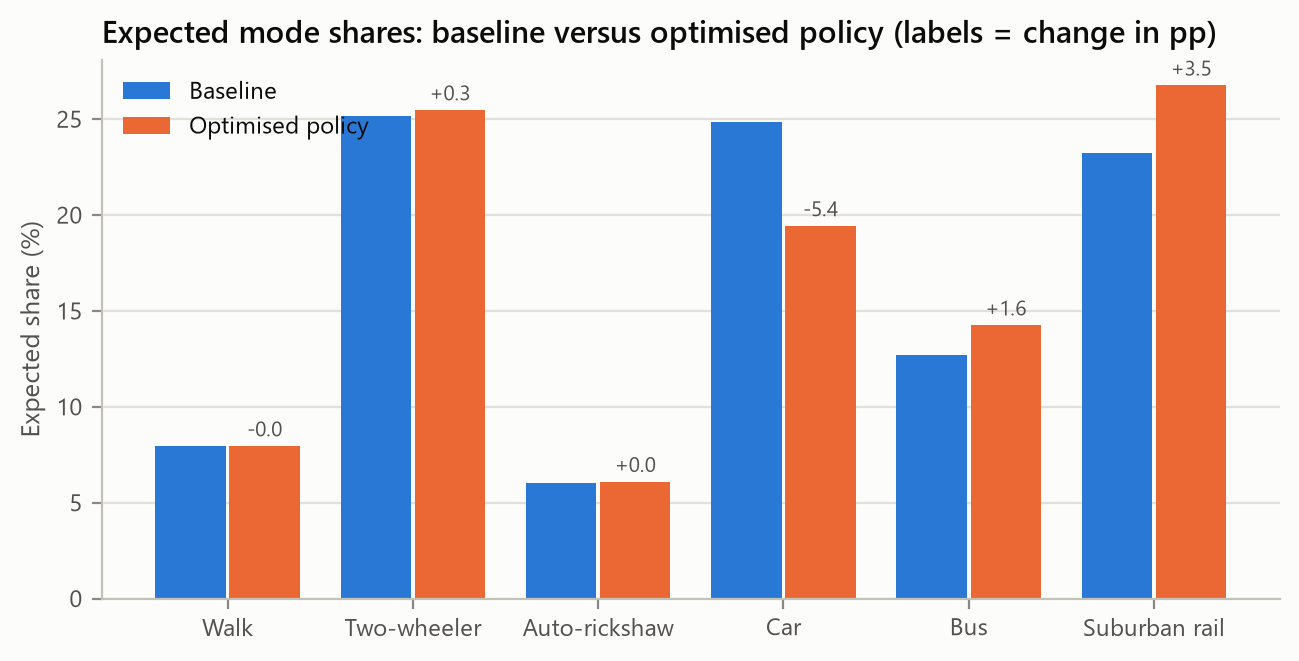

In [4]:
fig("optimisation_mode_shares.png", 800)

Under the MNL every lever moves the sustainable share in one direction, so the bounded optimum is the
corner where every lever sits at its upper bound. Grid search (46,585 points at 5% steps) and
differential evolution agree. The optimum raises the expected sustainable share from 43.91% to 48.99%
(+5.07 points), mostly by moving people out of cars (-5.4 points) into rail (+3.5) and bus (+1.6).

## Benchmarks

,policy,bus_time_red,bus_fare_red,train_time_red,train_fare_red,car_cost_inc,effort,sustainable_share_pct
0,Baseline (no intervention),0.0,0.0,0.0,0.0,0.0,0.0,43.913
1,Only bus travel-time reduction at bound,30.0,0.0,0.0,0.0,0.0,1.0,44.105
2,Only bus fare reduction at bound,0.0,50.0,0.0,0.0,0.0,1.0,44.441
3,Only suburban rail travel-time reduction at bound,0.0,0.0,20.0,0.0,0.0,1.0,44.705
4,Only suburban rail fare reduction at bound,0.0,0.0,0.0,50.0,0.0,1.0,45.191
5,Only car out-of-pocket cost increase at bound,0.0,0.0,0.0,0.0,50.0,1.0,46.234
6,All levers at half their bound,15.0,25.0,10.0,25.0,25.0,2.5,46.576
7,"Public transport levers at bound, no car pricing",30.0,50.0,20.0,50.0,0.0,4.0,46.645
8,Optimised policy,30.0,50.0,20.0,50.0,50.0,5.0,48.987


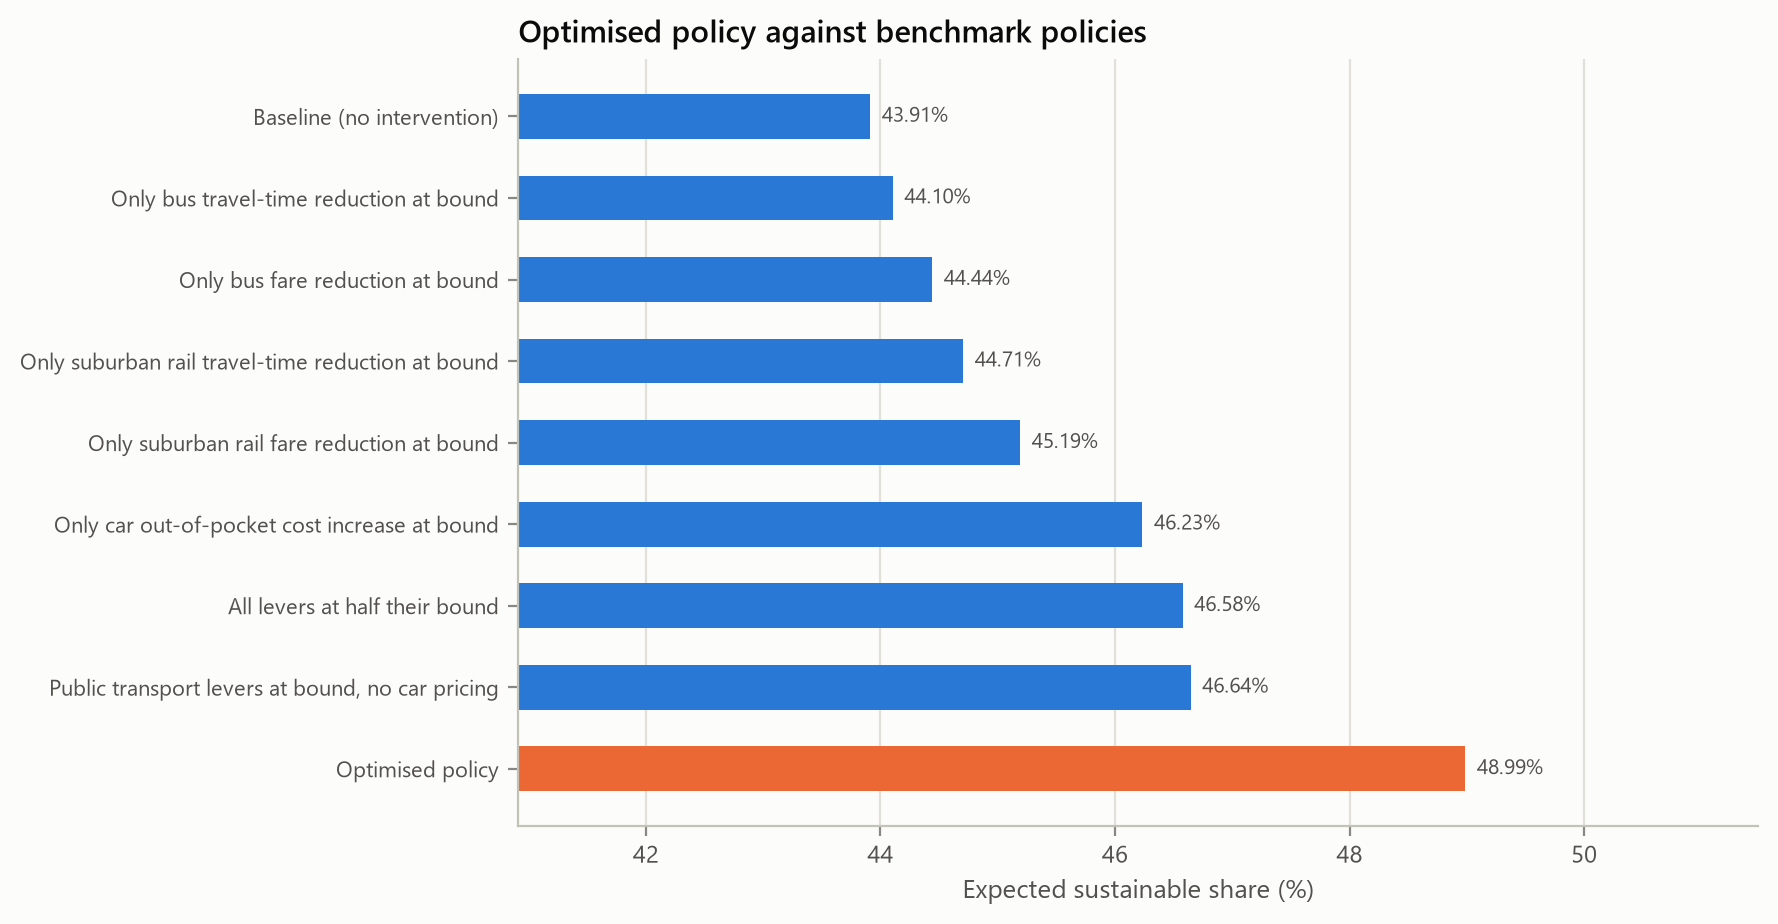

In [5]:
display(pd.read_csv(RES / "optimisation_benchmarks.csv").round(3))
fig("optimisation_benchmarks.png", 850)

## Effort budget: which levers come first?

,effort_budget,bus_time_red,bus_fare_red,train_time_red,train_fare_red,car_cost_inc,effort_used,sustainable_share_pct
0,0.25,0.0,0.0,0.0,0.0,10.0,0.2,44.454
1,0.50,0.0,0.0,0.0,0.0,25.0,0.5,45.187
2,1.00,0.0,0.0,0.0,0.0,50.0,1.0,46.234
3,1.50,0.0,0.0,0.0,25.0,50.0,1.5,46.893
4,2.00,0.0,0.0,0.0,50.0,50.0,2.0,47.561
5,2.50,0.0,0.0,10.0,50.0,50.0,2.5,47.962
6,3.00,0.0,0.0,20.0,50.0,50.0,3.0,48.360
7,4.00,0.0,50.0,20.0,50.0,50.0,4.0,48.844
8,5.00,30.0,50.0,20.0,50.0,50.0,5.0,48.987


,effort_budget,grid_best_pct,de_best_pct,de_effort,de_bus_time_red,de_bus_fare_red,de_train_time_red,de_train_fare_red,de_car_cost_inc
0,1.0,46.234,46.234,1.0,0.001,0.001,0.0,0.005,49.992
1,2.0,47.561,47.560,2.0,0.000,0.007,0.0,49.994,49.997


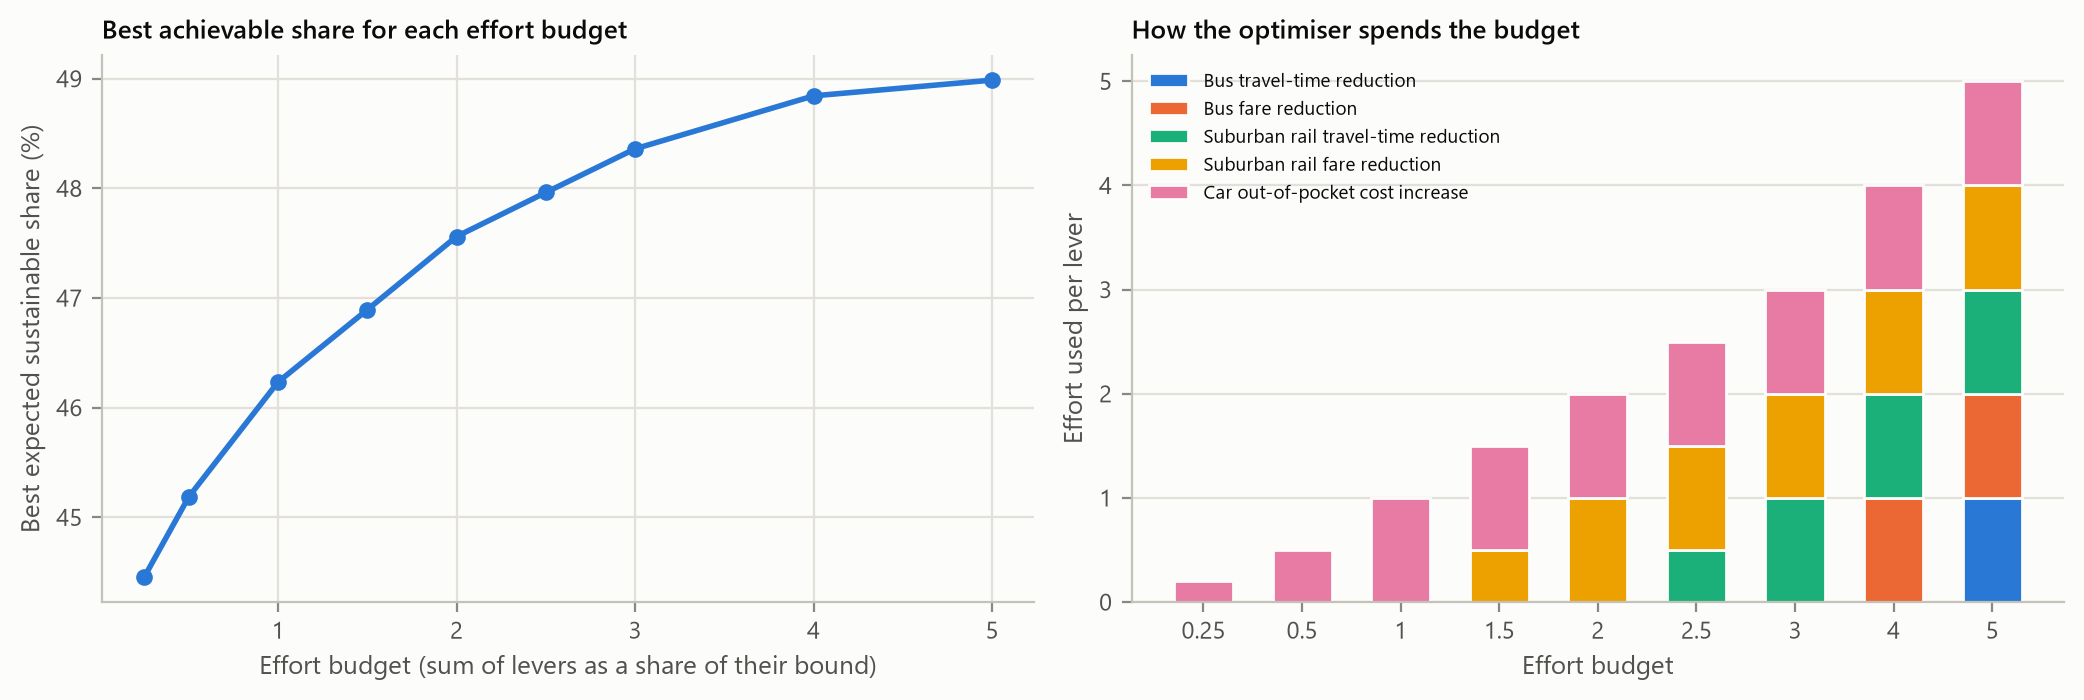

In [6]:
display(pd.read_csv(RES / "optimisation_effort_budget.csv").round(3))
display(pd.read_csv(RES / "optimisation_budget_de_check.csv").round(3))
fig("optimisation_effort_budget.png", 950)

When the total effort is limited, the optimiser spends it in a fixed order: car pricing first, then the
rail fare, rail time, bus fare and finally bus time. Differential evolution under the same budgets
lands on the grid's answer.

## Robustness to the walk-time weight

In [7]:
pd.read_csv(RES / "sensitivity_walk_weight.csv").round(3)

,walk_weight,log_likelihood,B_time,B_cost,VOT_INR_per_hour,baseline_pct,all_levers_at_bound_pct,gain_bus_time_red_pp,gain_bus_fare_red_pp,gain_train_time_red_pp,gain_train_fare_red_pp,gain_car_cost_inc_pp
0,1.5,-359.029,-0.032,-0.048,39.958,43.961,49.185,0.250,0.516,1.027,1.227,2.262
1,2.0,-358.400,-0.024,-0.050,29.601,43.913,48.987,0.192,0.528,0.793,1.278,2.321
2,2.5,-358.076,-0.020,-0.051,23.392,43.882,48.856,0.155,0.535,0.642,1.310,2.358
3,3.0,-357.883,-0.017,-0.051,19.294,43.861,48.765,0.130,0.539,0.538,1.332,2.382


Across walk weights from 1.5 to 3, the optimised share moves only between 48.8% and 49.2%, and the
ranking of the cost levers does not change. The rail-time effect is the one that depends on the
assumption (1.0 points at weight 1.5, 0.5 at weight 3).

## Independent verification

The objective is recomputed from scratch: the frozen model and the population are reloaded from disk,
the policy is applied with the general data-frame path (not the fast evaluator used by the search)
and every constraint is checked.

In [8]:
model, _ = load_frozen()
pop = pd.read_csv(C.Paths().synthetic / "synthetic_population.csv")
check = PO.verify_solution(res["optimal_levers"], res["objective_sustainable_share_pct"] / 100, model, pop)
check

{'recomputed_objective': 0.489870124739592,
 'reported_objective': 0.489870124739592,
 'abs_difference': 0.0,
 'matches': True,
 'constraint_problems': [],
 'non_negative_times': True,
 'non_negative_costs': True,
 'availability_unchanged': True,
 'probabilities_valid': True}